# 18 — Recursos y carga de trabajo por departamento
Hasta aquí la comparación entre departamentos mide **volumen y resultado** (causas, tasa de resolución, duración). Falta lo que explica la carga: **cuántos recursos** hay para atenderla.
El proyecto ya tiene, por departamento, los **ítems de personal** del cuadro 14.1.3 (puestos presupuestados, con los vacantes o *acéfalos* separados) y los **órganos judiciales**
del capítulo 4 (juzgados, tribunales y salas). Este notebook los cruza con el movimiento de **todas las materias** del notebook 14 (cuadros 9.1.3, 9.1.7 y 9.1.11) para responder:

1. ¿Cuántas causas ingresa, resuelve y acumula cada departamento **por puesto de trabajo ocupado**?
2. ¿Esa carga por puesto se relaciona con la tasa de resolución, la congestión o la duración?
3. ¿Cuántos puestos más (o menos) tendría cada departamento si todos tuvieran la **carga mediana**? (aritmética, no una recomendación)

Con 9 departamentos no hay potencia estadística para afirmar relaciones: se reportan los coeficientes con su valor *p* y se dice qué se puede y qué no se puede concluir.
Todo es **archivo nuevo** en `data/curated/eda/`.

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/flujo.ipynb
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

OUT_EDA = CURATED / "eda"
OUT_EDA.mkdir(parents=True, exist_ok=True)
ANALITICO = PROCESSED / "analitico"

personal = pd.read_parquet(ANALITICO / "personal_geografia.parquet")
recursos = pd.read_parquet(ANALITICO / "recursos_judiciales_geografia.parquet")
dep = pd.read_csv(OUT_EDA / "indicadores_capitulo9_departamento.csv")
print(len(personal), "distritos con personal;", len(recursos), "territorios con órganos;", len(dep), "departamentos con movimiento")

9 distritos con personal; 19 territorios con órganos; 9 departamentos con movimiento


## Controles antes de cruzar
- Los ítems publicados por distrito deben ser la suma de ocupados por mujeres, por varones y vacantes.
- Los órganos por departamento salen de sumar capital y provincias; se compara el total con el publicado.
- Los nueve departamentos deben aparecer una sola vez en cada fuente, y el movimiento debe ser el del notebook 14 (mismas ingresadas y resueltas).

In [2]:
assert (personal["items_mujer"] + personal["items_varon"] + personal["items_acefalias"] == personal["items_total"]).all(), "los ítems no suman"
assert (personal["remun_mujer"] + personal["remun_varon"] + personal["remun_acefalias"] == personal["remun_total"]).all() or \
       (personal["remun_mujer"] + personal["remun_varon"] + personal["remun_acefalias"] - personal["remun_total"]).abs().max() <= 5
assert personal["departamento_derivado"].is_unique and len(personal) == 9
recursos = recursos.copy()
for c in ["juzgados_publicados", "tribunales_publicados", "salas_publicadas", "total_publicado_fuente"]:
    recursos[c] = recursos[c].astype("float")
recursos["organos"] = recursos[["juzgados_publicados", "tribunales_publicados", "salas_publicadas"]].fillna(0).sum(axis=1)
organos = recursos.groupby("departamento_derivado")["organos"].sum()
assert len(organos) == 9
assert set(personal["departamento_derivado"]) == set(dep["departamento"]) == set(organos.index)
nac = pd.read_csv(OUT_EDA / "indicadores_capitulo9_materia.csv")
nac = nac[nac["ambito"] == "nacional"]
assert int(dep["ingresadas"].sum()) == int(nac["ingresadas"].sum()) and int(dep["resueltas"].sum()) == int(nac["resueltas"].sum())
print("ítems totales:", int(personal["items_total"].sum()), "| vacantes:", int(personal["items_acefalias"].sum()),
      "| órganos (juzgados + tribunales + salas):", int(organos.sum()))
print("controles OK: ítems = mujeres + varones + vacantes, 9 departamentos en las tres fuentes, movimiento igual al del notebook 14")

ítems totales: 6766 | vacantes: 316 | órganos (juzgados + tribunales + salas): 1209
controles OK: ítems = mujeres + varones + vacantes, 9 departamentos en las tres fuentes, movimiento igual al del notebook 14


## Indicadores por puesto ocupado
Un **ítem** es un puesto de trabajo presupuestado; los vacantes (*acefalias*) no trabajan, así que la carga se mide por **puesto ocupado** = ítems − vacantes.
El Anuario publica la remuneración **mensual** del personal (solo el personal, no el presupuesto total del Órgano Judicial); para no inventar una unidad anual se usa un **índice relativo**:
la remuneración por causa resuelta de cada departamento dividida por la del total nacional (1,0 = el promedio del país).
No se compara el idioma monetario ni se anualiza.

In [3]:
m = dep.merge(personal[["departamento_derivado", "items_total", "items_acefalias", "remun_total"]], left_on="departamento", right_on="departamento_derivado") \
       .merge(organos.rename("organos").reset_index(), on="departamento_derivado", validate="1:1")
assert len(m) == 9
m["items_ocupados"] = m["items_total"] - m["items_acefalias"]
m["pct_vacantes"] = m["items_acefalias"] / m["items_total"] * 100
m["ingresadas_por_ocupado"] = m["ingresadas"] / m["items_ocupados"]
m["resueltas_por_ocupado"] = m["resueltas"] / m["items_ocupados"]
m["pendientes_por_ocupado"] = m["pendientes_fin"] / m["items_ocupados"]
m["ingresadas_por_organo"] = m["ingresadas"] / m["organos"]
m["ocupados_por_organo"] = m["items_ocupados"] / m["organos"]
nac_rem = m["remun_total"].sum() / m["resueltas"].sum()
m["indice_remuneracion_por_resuelta"] = (m["remun_total"] / m["resueltas"]) / nac_rem
mediana = float(m["ingresadas_por_ocupado"].median())
m["ocupados_para_carga_mediana"] = m["ingresadas"] / mediana
m["diferencia_ocupados_vs_carga_mediana"] = m["ocupados_para_carga_mediana"] - m["items_ocupados"]
cols = ["departamento", "items_total", "items_acefalias", "items_ocupados", "pct_vacantes", "organos", "ocupados_por_organo", "ingresadas", "resueltas", "pendientes_fin",
        "ingresadas_por_ocupado", "resueltas_por_ocupado", "pendientes_por_ocupado", "ingresadas_por_organo", "indice_remuneracion_por_resuelta",
        "tasa_resolucion", "tasa_congestion", "duracion_estimada_dias", "ocupados_para_carga_mediana", "diferencia_ocupados_vs_carga_mediana"]
m = m.sort_values("ingresadas_por_ocupado")
m[cols].round(3).to_csv(OUT_EDA / "recursos_carga_departamento.csv", index=False, encoding="utf-8")
assert abs(m["items_ocupados"].sum() - (personal["items_total"].sum() - personal["items_acefalias"].sum())) < 1e-9
print("Carga mediana: {:.1f} causas ingresadas por puesto ocupado".format(mediana))
print("Rango: de {:.1f} ({}) a {:.1f} ({}) = {:.1f} veces".format(m["ingresadas_por_ocupado"].min(), m.iloc[0]["departamento"], m["ingresadas_por_ocupado"].max(), m.iloc[-1]["departamento"],
      m["ingresadas_por_ocupado"].max() / m["ingresadas_por_ocupado"].min()))
m[["departamento", "items_ocupados", "pct_vacantes", "ingresadas_por_ocupado", "resueltas_por_ocupado", "pendientes_por_ocupado", "indice_remuneracion_por_resuelta",
   "tasa_resolucion", "duracion_estimada_dias", "diferencia_ocupados_vs_carga_mediana"]].round(2)

Carga mediana: 52.1 causas ingresadas por puesto ocupado
Rango: de 33.1 (Pando) a 84.8 (Santa Cruz) = 2.6 veces


,departamento,items_ocupados,pct_vacantes,ingresadas_por_ocupado,resueltas_por_ocupado,pendientes_por_ocupado,indice_remuneracion_por_resuelta,tasa_resolucion,duracion_estimada_dias,diferencia_ocupados_vs_carga_mediana
4,Pando,160,12.09,33.15,31.47,29.64,2.16,0.95,343.76,-58.27
0,Beni,403,2.42,38.17,32.64,34.81,1.83,0.85,389.37,-107.94
3,Chuquisaca,532,5.84,41.89,39.06,21.57,1.54,0.93,201.52,-104.56
8,Potosí,552,7.07,49.18,50.07,45.85,1.22,1.02,334.25,-31.36
1,Oruro,434,7.66,52.14,47.66,35.91,1.3,0.91,274.99,0.0
6,Tarija,507,2.87,57.09,55.64,47.12,1.05,0.97,309.09,48.2
7,Cochabamba,1077,3.15,66.02,65.6,44.8,0.9,0.99,249.23,286.66
5,La Paz,1480,5.13,66.17,62.89,63.5,0.93,0.95,368.54,398.31
2,Santa Cruz,1305,3.19,84.85,79.0,91.38,0.73,0.93,422.19,818.64


## ¿Se relaciona la carga por puesto con los resultados?
Correlación de Spearman (por rangos, robusta a valores extremos) entre cada medida de recursos o carga y cada resultado, con su valor *p*.
Con **n = 9** solo un coeficiente muy alto (alrededor de 0,7 o más en valor absoluto) sería significativo; lo demás no se puede distinguir de la casualidad.
La duración se calcula como pendientes ÷ resueltas, así que su relación con *pendientes por puesto* es en parte **mecánica** y no se interpreta.

In [4]:
medidas = ["ingresadas_por_ocupado", "resueltas_por_ocupado", "ocupados_por_organo", "pct_vacantes", "indice_remuneracion_por_resuelta"]
resultados = ["tasa_resolucion", "tasa_congestion", "duracion_estimada_dias"]
filas = []
for a in medidas:
    for b in resultados:
        rho, p = stats.spearmanr(m[a], m[b])
        filas.append({"medida": a, "resultado": b, "spearman": float(rho), "valor_p": float(p), "significativo_al_5pct": bool(p < 0.05), "n": len(m)})
cor = pd.DataFrame(filas)
cor.to_csv(OUT_EDA / "correlaciones_recursos_departamento.csv", index=False, encoding="utf-8")
rho_items_ing, p_items_ing = stats.spearmanr(m["items_ocupados"], m["ingresadas"])
print("ítems ocupados contra ingresadas (9 departamentos): Spearman {:.2f} (p = {:.4f}) → el personal se reparte casi proporcional a la demanda".format(rho_items_ing, p_items_ing))
print(int(cor["significativo_al_5pct"].sum()), "de", len(cor), "relaciones resultan significativas al 5 %")
cor.round(2)

ítems ocupados contra ingresadas (9 departamentos): Spearman 0.90 (p = 0.0009) → el personal se reparte casi proporcional a la demanda
0 de 15 relaciones resultan significativas al 5 %


,medida,resultado,spearman,valor_p,significativo_al_5pct,n
0,ingresadas_por_ocupado,tasa_resolucion,0.22,0.58,False,9
1,ingresadas_por_ocupado,tasa_congestion,0.17,0.67,False,9
2,ingresadas_por_ocupado,duracion_estimada_dias,0.17,0.67,False,9
3,resueltas_por_ocupado,tasa_resolucion,0.37,0.33,False,9
4,resueltas_por_ocupado,tasa_congestion,0.12,0.77,False,9
5,resueltas_por_ocupado,duracion_estimada_dias,0.12,0.77,False,9
6,ocupados_por_organo,tasa_resolucion,-0.23,0.55,False,9
7,ocupados_por_organo,tasa_congestion,0.53,0.14,False,9
8,ocupados_por_organo,duracion_estimada_dias,0.53,0.14,False,9
9,pct_vacantes,tasa_resolucion,0.07,0.86,False,9


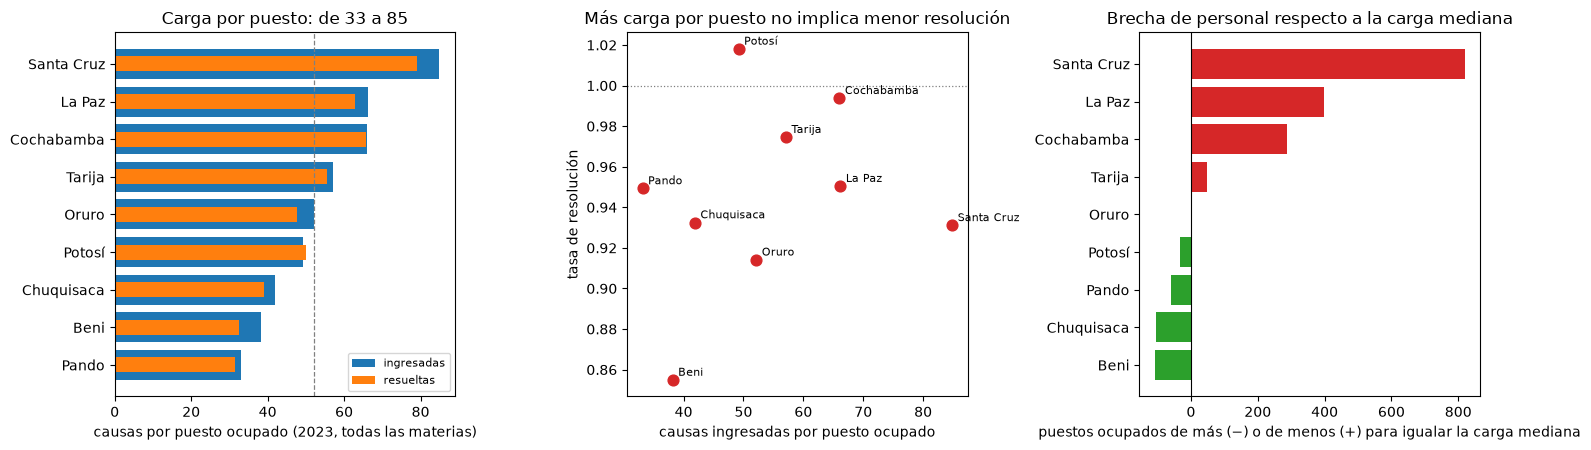

In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6))
orden = m.sort_values("ingresadas_por_ocupado")
ejes[0].barh(orden["departamento"], orden["ingresadas_por_ocupado"], color="tab:blue", label="ingresadas")
ejes[0].barh(orden["departamento"], orden["resueltas_por_ocupado"], color="tab:orange", height=0.4, label="resueltas")
ejes[0].axvline(mediana, color="gray", ls="--", lw=0.9)
ejes[0].set_xlabel("causas por puesto ocupado (2023, todas las materias)")
ejes[0].set_title("Carga por puesto: de {:.0f} a {:.0f}".format(m["ingresadas_por_ocupado"].min(), m["ingresadas_por_ocupado"].max()))
ejes[0].legend(fontsize=8)
ejes[1].scatter(m["ingresadas_por_ocupado"], m["tasa_resolucion"], s=60, color="tab:red")
for _, f in m.iterrows():
    ejes[1].annotate(f["departamento"], (f["ingresadas_por_ocupado"], f["tasa_resolucion"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ejes[1].axhline(1, color="gray", ls=":", lw=0.9)
ejes[1].set_xlabel("causas ingresadas por puesto ocupado")
ejes[1].set_ylabel("tasa de resolución")
ejes[1].set_title("Más carga por puesto no implica menor resolución")
d = m.sort_values("diferencia_ocupados_vs_carga_mediana")
colores = ["tab:green" if v < 0 else "tab:red" for v in d["diferencia_ocupados_vs_carga_mediana"]]
ejes[2].barh(d["departamento"], d["diferencia_ocupados_vs_carga_mediana"], color=colores)
ejes[2].axvline(0, color="black", lw=0.8)
ejes[2].set_xlabel("puestos ocupados de más (−) o de menos (+) para igualar la carga mediana")
ejes[2].set_title("Brecha de personal respecto a la carga mediana")
plt.tight_layout()
plt.show()

## Lectura (con sus límites)
- **La carga por puesto ocupado varía 2,6 veces** (de 33 en Pando a 85 en Santa Cruz; mediana 52). Santa Cruz, La Paz y Cochabamba están por encima de la mediana; Pando, Beni, Chuquisaca y Potosí, por debajo.
- **El personal se reparte casi proporcional a la demanda** (ítems ocupados contra ingresadas: Spearman 0,90, *p* < 0,001). Las diferencias de carga por puesto vienen de cuánto se aparta cada departamento de esa proporción.
- **Ninguna de las 15 relaciones entre recursos y resultados es significativa** (la más alta, ocupados por órgano contra congestión, tiene *p* = 0,14). Con 9 departamentos eso **no prueba que no haya relación**: solo que estos datos no la detectan. La tasa de congestión y la duración dan el mismo coeficiente porque, entre departamentos, ordenan igual; no son dos pruebas independientes.
- **Dos clases de problema, descriptivamente**: *saturación* (Santa Cruz: la mayor carga por puesto, la remuneración por causa resuelta más baja del país, la mayor duración y el mayor aumento absoluto de stock) y *bajo rendimiento con carga ligera* (Beni: 38 causas ingresadas por puesto, 33 resueltas por puesto, la única tasa de resolución crítica). No es lo mismo ni se arregla igual.
- La **remuneración por causa resuelta** varía 3 veces (índice de 0,73 en Santa Cruz a 2,16 en Pando): los departamentos chicos pagan más por resolución, lo esperable con estructuras fijas.
- La «**brecha de personal**» es **aritmética de igualdad de carga**, no una recomendación: ignora la mezcla de materias (penal y civil no pesan igual por causa), que el ítem incluye personal administrativo y de apoyo, y que no se sabe cuántos puestos son jueces.
- Falta la **población** (INE) para pasar de causas por puesto a causas por 100.000 habitantes; sin ella no se puede separar «hay más litigio» de «hay menos acceso».